# TP — Régimes de marche de l'atelier connecté (K-means)

**Question du responsable de production :** les six machines fonctionnent-elles toutes de la même manière, ou existe-t-il des régimes de marche distincts ?

Plan : (1) K-means « maison » NumPy vs scikit-learn · (2) choix de *k* · (3) segmentation et profilage · (4) noms et actions · (5) effet de la standardisation.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

# Chemin : adapter si besoin (le TP utilise tp/data/atelier_connecte.csv)
for chemin in ["tp/data/atelier_connecte.csv", "atelier_connecte.csv",
               "/mnt/user-data/uploads/atelier_connecte__2_.csv"]:
    if os.path.exists(chemin):
        break
df = pd.read_csv(chemin)

mesures = ["temperature", "vibration", "courant", "cadence"]
print(df.shape, "| valeurs manquantes :", df[mesures].isna().sum().to_dict())

# Préparation identique au TP 1 : imputation par la médiane, puis standardisation.
# (colonnes défaut, alarme_*, vibration_pic, vib_f* : jamais utilisées pour segmenter)
X_orig = df[mesures].fillna(df[mesures].median())
X_std = StandardScaler().fit_transform(X_orig)
print(X_orig.describe().round(2))
print("\nCorrélations :\n", X_orig.corr().round(2))

(720, 17) | valeurs manquantes : {'temperature': 24, 'vibration': 32, 'courant': 30, 'cadence': 18}
       temperature  vibration  courant  cadence
count       720.00     720.00   720.00   720.00
mean         75.91       2.85    14.53    48.82
std           5.96       1.30     2.72     7.28
min          62.46       0.15     8.68    25.15
25%          71.28       1.82    12.41    43.86
50%          76.13       2.73    14.57    48.81
75%          80.21       3.60    16.37    54.47
max          94.63       7.17    22.87    67.54

Corrélations :
              temperature  vibration  courant  cadence
temperature         1.00       0.82     0.84    -0.80
vibration           0.82       1.00     0.84    -0.80
courant             0.84       0.84     1.00    -0.82
cadence            -0.80      -0.80    -0.82     1.00


## 1. K-means « maison » avec NumPy

Algorithme de Lloyd : on alterne (a) **affectation** de chaque point au centroïde le plus proche, (b) **mise à jour** de chaque centroïde par la moyenne de son groupe, jusqu'à stabilité des affectations. Initialisation : *k* points tirés au hasard (version simplifiée, sans k-means++). Un cluster qui se vide est ré-initialisé sur le point le plus éloigné de son centroïde.

In [2]:
def kmeans_numpy(X, k, n_iter=300, seed=0):
    """K-means de Lloyd. Retourne (labels, centroïdes, inertie)."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    centres = X[rng.choice(len(X), size=k, replace=False)].copy()
    labels = np.full(len(X), -1)
    for _ in range(n_iter):
        # (a) affectation : distances² (n, k) puis argmin
        d2 = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
        nouveaux = d2.argmin(axis=1)
        if np.array_equal(nouveaux, labels):          # convergence
            break
        labels = nouveaux
        # (b) mise à jour des centroïdes
        for j in range(k):
            membres = X[labels == j]
            if len(membres):
                centres[j] = membres.mean(axis=0)
            else:                                      # cluster vide -> point le plus loin
                dist = d2[np.arange(len(X)), labels]
                centres[j] = X[dist.argmax()]
    inertie = ((X - centres[labels]) ** 2).sum()
    return labels, centres, inertie

K = 4
essais = [kmeans_numpy(X_std, K, seed=s) for s in range(20)]
inerties = np.array([e[2] for e in essais])
print("Inerties des 20 graines :", np.sort(inerties).round(1))
labels_np, centres_np, inertie_np = essais[int(inerties.argmin())]

sk = KMeans(n_clusters=K, n_init=20, init="k-means++", random_state=SEED).fit(X_std)
print(f"\nInertie NumPy (meilleure graine) : {inertie_np:.3f}")
print(f"Inertie scikit-learn             : {sk.inertia_:.3f}")
print(f"ARI NumPy vs scikit-learn        : {adjusted_rand_score(labels_np, sk.labels_):.3f}")

Inerties des 20 graines : [616.  616.  616.  616.  616.  616.  616.  644.8 644.8 644.8 644.8 644.8
 644.8 644.8 644.8 645.1 645.1 645.1 645.1 645.1]

Inertie NumPy (meilleure graine) : 616.009
Inertie scikit-learn             : 616.023
ARI NumPy vs scikit-learn        : 0.992


**Lecture.** Les inerties sont quasi identiques (616,01 vs 616,02) et l'ARI vaut ≈ 0,99 : les deux implémentations trouvent pratiquement la même partition (l'écart tient à quelques points frontières, dû à l'initialisation). K-means ne garantit qu'un **minimum local**, d'où l'intérêt de plusieurs graines et de garder la meilleure inertie (c'est ce que fait `n_init` dans scikit-learn). Les graines à 644,8 ou 645,1 ci-dessus illustrent ce risque.

## 2. Choisir *k* : coude et silhouette

 k  inertie  silhouette  gain_inertie_%
 2 1154.146       0.493             NaN
 3  766.588       0.411            33.6
 4  616.023       0.389            19.6
 5  503.229       0.319            18.3
 6  469.478       0.269             6.7
 7  439.624       0.224             6.4
 8  415.150       0.227             5.6


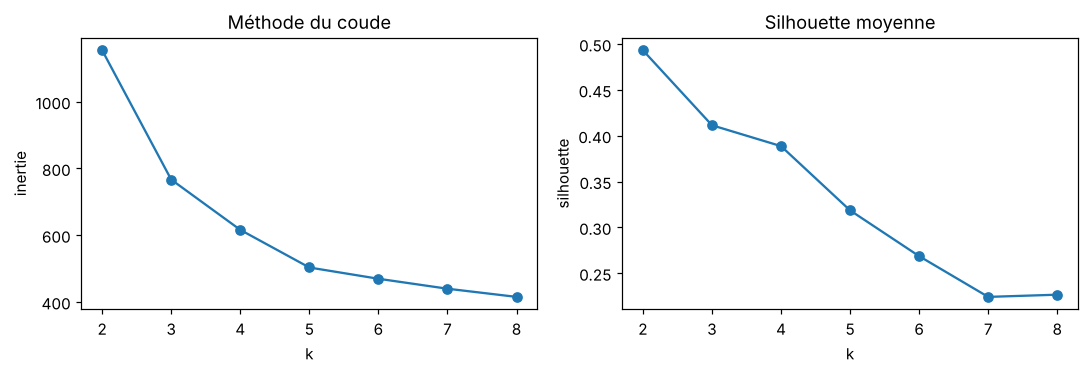

In [3]:
scores = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=20, init="k-means++", random_state=SEED).fit(X_std)
    scores.append((k, m.inertia_, silhouette_score(X_std, m.labels_)))
tableau = pd.DataFrame(scores, columns=["k", "inertie", "silhouette"])
tableau["gain_inertie_%"] = (-tableau["inertie"].pct_change() * 100).round(1)
print(tableau.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(tableau["k"], tableau["inertie"], "o-")
axes[0].set(title="Méthode du coude", xlabel="k", ylabel="inertie")
axes[1].plot(tableau["k"], tableau["silhouette"], "o-")
axes[1].set(title="Silhouette moyenne", xlabel="k", ylabel="silhouette")
plt.tight_layout()
plt.show()

**Que suggère chaque courbe ?**

- **Coude** : l'inertie baisse vite de *k* = 2 à 4 (≈ −34 % puis −20 %), puis les gains se tassent nettement (≈ −18 % → −7 % → −5 %). Le coude est **doux, situé autour de *k* = 3-4**, il n'y a pas de cassure franche.
- **Silhouette** : maximale pour *k* = 2 (≈ 0,49) puis décroissante (0,41 pour 3, 0,39 pour 4, ≈ 0,32 pour 5). Aucune valeur n'atteint 0,5 : la structure est **réelle mais peu tranchée**. Les quatre mesures sont fortement corrélées (|r| ≈ 0,80-0,84) : les données ressemblent plus à un **continuum de charge** qu'à des blocs bien séparés. Un *k* = 2 « marche normale / marche chargée » est le découpage le plus net mais aussi le plus grossier.

## 3. Segmentation retenue

**Choix : *k* = 4.** Justification :
1. *Indicateurs* : *k* = 4 est encore dans la zone du coude (gain d'inertie ≈ 20 % sur *k* = 3) et garde une silhouette acceptable (≈ 0,39), proche de celle de *k* = 3 ; au-delà, la silhouette s'effondre (< 0,32).
2. *Besoin de maintenance* : *k* = 2 ou 3 noie dans un même groupe les points les plus extrêmes ; *k* = 4 isole un petit régime très chaud / vibrant / à faible cadence, qui concentre l'essentiel des défauts (colonne `defaut`, **non utilisée** pour segmenter, donc validation indépendante).
3. *Opérationnel* : quatre régimes restent gérables par l'équipe de maintenance (un seuil d'alerte et une action par régime).

In [4]:
K = 4
km = KMeans(n_clusters=K, n_init=20, init="k-means++", random_state=SEED).fit(X_std)

# Renumérotation : régimes ordonnés par température médiane croissante (R1 = le plus froid)
df["cluster_brut"] = km.labels_
ordre = (X_orig.assign(c=km.labels_).groupby("c")["temperature"].median()
         .sort_values().index.tolist())
mapping = {ancien: nouveau for nouveau, ancien in enumerate(ordre, start=1)}
df["regime"] = df["cluster_brut"].map(mapping)

profil = (df.groupby("regime")
            .agg(effectif=("regime", "size"),
                 temperature=("temperature", "median"),
                 vibration=("vibration", "median"),
                 courant=("courant", "median"),
                 cadence=("cadence", "median"),
                 taux_defaut=("defaut", "mean")))
profil.insert(1, "part_%", (100 * profil["effectif"] / len(df)).round(1))
profil["taux_defaut"] = (100 * profil["taux_defaut"]).round(1)
profil = profil.rename(columns={"taux_defaut": "taux_defaut_%"})
# médianes calculées sur les valeurs observées (NaN ignorés), en unités d'origine
print(profil.round(2).to_string())
print("\nTaux de défaut global : %.1f %%" % (100 * df["defaut"].mean()))

        effectif  part_%  temperature  vibration  courant  cadence  taux_defaut_%
regime                                                                           
1            299    41.5        70.54       1.68    12.02    55.51            2.7
2            239    33.2        77.33       3.01    15.14    47.16            7.1
3            149    20.7        82.04       4.18    17.36    41.40           19.5
4             33     4.6        88.38       6.23    20.48    32.72           75.8

Taux de défaut global : 11.0 %


In [5]:
croise = pd.crosstab(df["machine_id"], df["regime"], margins=True, margins_name="Total")
print("Effectifs machine x régime :\n", croise, "\n")
print("Répartition en % de chaque machine :\n",
      (pd.crosstab(df["machine_id"], df["regime"], normalize="index") * 100).round(0).astype(int))
print("\nDéfauts par régime et par machine :\n",
      pd.crosstab(df["machine_id"], df["regime"], values=df["defaut"], aggfunc="sum").fillna(0).astype(int))

Effectifs machine x régime :
 regime        1    2    3   4  Total
machine_id                          
M-01        108   11    1   0    120
M-02        105    5   10   0    120
M-03          2  106    6   6    120
M-04          0   90   19  11    120
M-05         84   24   12   0    120
M-06          0    3  101  16    120
Total       299  239  149  33    720 

Répartition en % de chaque machine :
 regime       1   2   3   4
machine_id                
M-01        90   9   1   0
M-02        88   4   8   0
M-03         2  88   5   5
M-04         0  75  16   9
M-05        70  20  10   0
M-06         0   2  84  13

Défauts par régime et par machine :
 regime      1  2  3   4
machine_id             
M-01        4  7  0   0
M-02        2  1  7   0
M-03        0  4  6   4
M-04        0  3  3   8
M-05        2  2  8   0
M-06        0  0  5  13


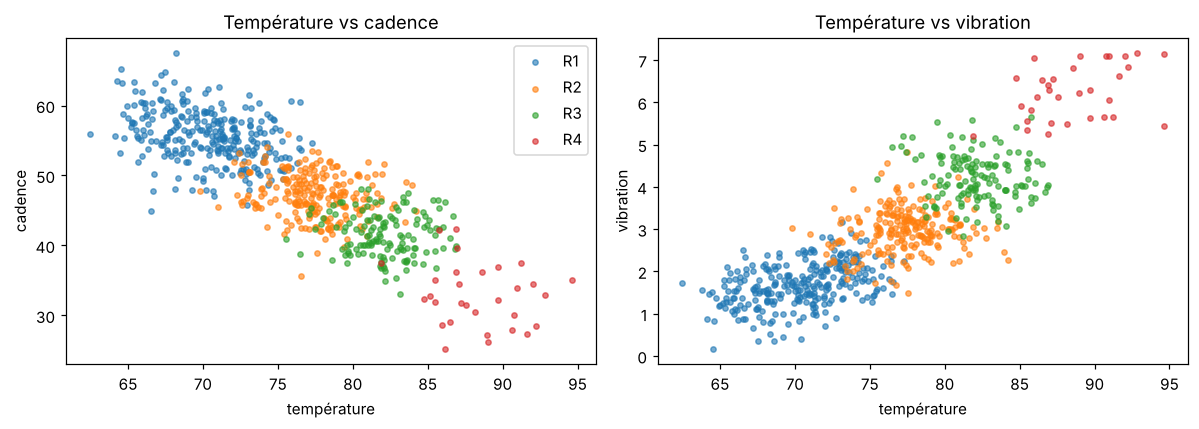

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r in sorted(df["regime"].unique()):
    s = df[df["regime"] == r]
    ax[0].scatter(s["temperature"], s["cadence"], s=12, alpha=.6, label=f"R{r}")
    ax[1].scatter(s["temperature"], s["vibration"], s=12, alpha=.6, label=f"R{r}")
ax[0].set(xlabel="température", ylabel="cadence", title="Température vs cadence")
ax[1].set(xlabel="température", ylabel="vibration", title="Température vs vibration")
ax[0].legend()
plt.tight_layout(); plt.show()

## 4. Noms et actions

In [7]:
tab_actions = pd.DataFrame({
    "régime": ["R1", "R2", "R3", "R4"],
    "nom (prudent)": [
        "Marche froide, cadence haute",
        "Marche intermédiaire",
        "Marche chargée, cadence réduite",
        "Marche extrême (à surveiller)",
    ],
    "action": [
        "Seuils d'alerte nominaux ; contrôle périodique standard (fréquence minimale).",
        "Seuils d'alerte spécifiques à ce régime ; suivi des dérives (tendance vibration / courant) sur ces machines.",
        "Contrôle renforcé : inspection mécanique ciblée (roulements, alignement, refroidissement), "
        "recalage du réglage de charge/cadence si possible.",
        "Contrôle prioritaire sous 24-48 h ; vérification terrain avant de conclure à une panne ; "
        "seuil d'alerte précoce pour détecter l'entrée dans ce régime.",
    ],
})
print(tab_actions.to_string(index=False))

régime                   nom (prudent)                                                                                                                                                 action
    R1    Marche froide, cadence haute                                                                          Seuils d'alerte nominaux ; contrôle périodique standard (fréquence minimale).
    R2            Marche intermédiaire                                           Seuils d'alerte spécifiques à ce régime ; suivi des dérives (tendance vibration / courant) sur ces machines.
    R3 Marche chargée, cadence réduite          Contrôle renforcé : inspection mécanique ciblée (roulements, alignement, refroidissement), recalage du réglage de charge/cadence si possible.
    R4   Marche extrême (à surveiller) Contrôle prioritaire sous 24-48 h ; vérification terrain avant de conclure à une panne ; seuil d'alerte précoce pour détecter l'entrée dans ce régime.


Les noms décrivent ce qui est **mesuré**, pas une cause : « chargée » et « extrême » ne disent pas si la machine est mal réglée, usée ou simplement sollicitée par la production. Une confirmation terrain est nécessaire avant toute décision lourde (arrêt, remplacement).

## 5. Effet de la standardisation

In [8]:
km_brut = KMeans(n_clusters=K, n_init=20, init="k-means++", random_state=SEED).fit(X_orig.values)
print("Variances des variables brutes :\n", X_orig.var().round(2).to_dict())
print(f"\nARI (avec vs sans standardisation) : {adjusted_rand_score(km.labels_, km_brut.labels_):.3f}")
print(f"Silhouette (calculée dans l'espace de chaque modèle) : standardisé {silhouette_score(X_std, km.labels_):.3f}"
      f" | brut {silhouette_score(X_orig.values, km_brut.labels_):.3f}")

df["regime_brut_cluster"] = km_brut.labels_
ordre_b = (X_orig.assign(c=km_brut.labels_).groupby("c")["temperature"].median()
           .sort_values().index.tolist())
df["regime_brut"] = df["regime_brut_cluster"].map({a: i for i, a in enumerate(ordre_b, 1)})

print("\nTable de contingence (lignes : standardisé, colonnes : brut)")
print(pd.crosstab(df["regime"], df["regime_brut"]))
profil_b = (df.groupby("regime_brut")
              .agg(effectif=("regime_brut", "size"), temperature=("temperature", "median"),
                   vibration=("vibration", "median"), courant=("courant", "median"),
                   cadence=("cadence", "median"), taux_defaut=("defaut", "mean")))
profil_b["taux_defaut"] = (100 * profil_b["taux_defaut"]).round(1)
print("\nProfil sans standardisation :\n", profil_b.round(2).to_string())

Variances des variables brutes :
 {'temperature': 35.54, 'vibration': 1.7, 'courant': 7.38, 'cadence': 52.96}

ARI (avec vs sans standardisation) : 0.439
Silhouette (calculée dans l'espace de chaque modèle) : standardisé 0.389 | brut 0.342

Table de contingence (lignes : standardisé, colonnes : brut)
regime_brut    1   2    3   4
regime                       
1            202  97    0   0
2              0  93  145   1
3              0   0   68  81
4              0   0    0  33

Profil sans standardisation :
              effectif  temperature  vibration  courant  cadence  taux_defaut
regime_brut                                                                 
1                 202        69.20       1.56    11.66    56.93          2.5
2                 190        74.02       2.30    13.38    50.81          6.8
3                 213        79.17       3.25    16.00    45.35         10.8
4                 115        83.61       4.54    17.99    38.69         33.0


### Ce qui change sans standardisation

- L'accord avec la partition précédente est **faible (ARI ≈ 0,44)**.
- Sans mise à l'échelle, les variables à grande variance (**cadence**, variance ≈ 53, et **température**, ≈ 36) dominent la distance ; **vibration** (≈ 1,7) et **courant** (≈ 7) pèsent très peu. Les clusters deviennent des tranches de « température + cadence » et dépendent des unités.
- Conséquence métier : le régime le plus critique est **noyé** dans un groupe de 115 points (taux de défaut ≈ 33 %) au lieu de 33 points (≈ 76 %). Les 33 points extrêmes restent regroupés, mais avec 82 points moins extrêmes ; la détection des cas à risque est donc moins nette.
- Ici les variables sont très corrélées, ce qui limite les dégâts (les profils restent ordonnés de façon similaire), mais la standardisation reste nécessaire dès que les unités diffèrent.

## Synthèse

- **Les six machines ne fonctionnent pas de la même manière.** M-01, M-02 et M-05 sont surtout en R1 ; M-03 et M-04 en R2 ; M-06 en R3, et c'est elle qui compte le plus de points R4 (16 sur 33).
- Le taux de défaut augmente de façon monotone avec le régime : 2,7 % → 7,1 % → 19,5 % → 75,8 % (global 11 %), alors que `defaut` n'a pas servi à segmenter.
- **Limites** : silhouette modeste (≈ 0,39), continuum plutôt que blocs ; les régimes recoupent en grande partie l'identité des machines, donc « régime » et « machine » sont en partie confondus. Les colonnes `regime_reference` et `equipe` ne figurent pas dans ce fichier, les pistes « pour aller plus loin » n'ont donc pas été traitées.